# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Polonska"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

Saving weather_forecast.csv to weather_forecast.csv
Saving train.csv to train.csv
history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

In [5]:
import lightgbm as lgb
W = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "daylight", "air_density"]

def blend_forecast(hist, wx):
    """50% LightGBM (weather + level) + 50% seasonal naive, fitted on all of `hist`."""
    df = pd.concat([hist, wx.assign(y=np.nan)], ignore_index=True)
    y48 = df.y.shift(48)                                      # y-based features lagged >= 48 h
    lvl = y48.rolling(72, min_periods=24).mean()              # 3-day level: the target is y / level
    doy = 2 * np.pi * df.ds.dt.dayofyear / 365.25
    X = df[W].astype(float).assign(
        hour=df.ds.dt.hour, doy_s=np.sin(doy), doy_c=np.cos(doy), wind3=df.wind_speed ** 3,
        cc3=df.cloud_cover.rolling(3, center=True, min_periods=1).mean(), lvl3=lvl,
        lvl7=y48.rolling(168, min_periods=24).mean(), max3=y48.rolling(72, min_periods=24).max(),
        max14=y48.rolling(336, min_periods=24).max(), lag48=y48, lag72=df.y.shift(72), lag168=df.y.shift(168),
        night7=df.y.where(df.daylight == 0).shift(48).rolling(168, min_periods=12).mean())
    n = len(hist); tr = (X.index < n) & (lvl > 1)
    m = lgb.train(dict(learning_rate=0.03, min_data_in_leaf=50, feature_fraction=0.8, bagging_fraction=0.8,
                       bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=0),
                  lgb.Dataset(X[tr], (df.y / lvl)[tr]), 300)
    p = np.clip(m.predict(X[n:]) * lvl[n:].values, 0, None)
    return 0.5 * p + 0.5 * snaive(hist.y.values)[0], lvl[n:].values

# Backtest on every day since 1 Sep that ends before the validation window -> errors for the interval.
errs = []
for o in data.index[(data.ds >= "2026-09-01") & (data.ds.dt.hour == 1)]:
    if o + H > len(past): break
    p, lv = blend_forecast(data[:o], data[o:o + H].drop(columns="y"))
    errs.append(pd.DataFrame({"z": (y[o:o + H] - p) / lv, "day": data.daylight.values[o:o + H]}))
q = pd.concat(errs).groupby("day").z.quantile([0.025, 0.975]).unstack()   # rows: night/day

def with_interval(p, lv, day):
    qq = q.loc[day].values
    return p, np.minimum(np.clip(p + qq[:, 0] * lv, 0, None), p), np.maximum(p + qq[:, 1] * lv, p)

# Validation on the benchmark's window.
p, lv = blend_forecast(data[:len(past)], data[len(past):].drop(columns="y"))
results.loc["LightGBM + snaive"] = score(valid, *with_interval(p, lv, data.daylight.values[len(past):]))
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0
LightGBM + snaive,106.035,61.386,484.326,1.0


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

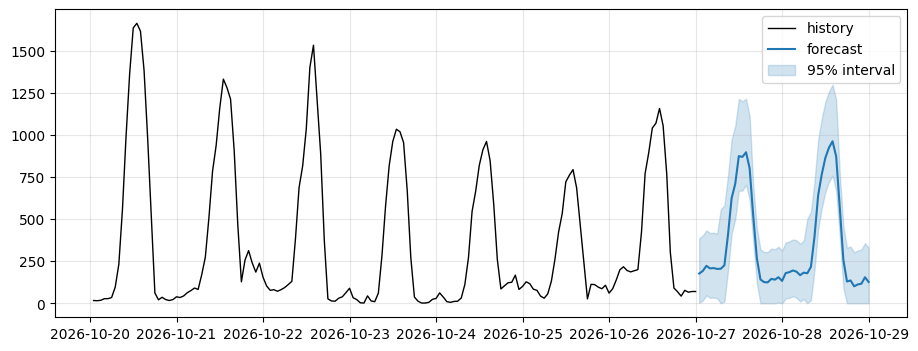

In [6]:
p, lv = blend_forecast(data, weather_fc)          # fit on the whole history
forecast, lower_95, upper_95 = with_interval(p, lv, weather_fc.daylight.values)

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [7]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved POLONSKA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.